In [1]:
import numpy as np

data = np.load("data/preprocessed_data.npz")

print("Available arrays:", data.files)

for name in data.files:
    arr = data[name]
    print(name, "Shape:", arr.shape, "Data type:", arr.dtype)

Available arrays: ['X_train', 'Y_train', 'X_val', 'Y_val', 'X_test', 'Y_test']
X_train Shape: (116016, 32) Data type: int32
Y_train Shape: (116016, 42) Data type: int32
X_val Shape: (14502, 32) Data type: int32
Y_val Shape: (14502, 42) Data type: int32
X_test Shape: (14503, 32) Data type: int32
Y_test Shape: (14503, 42) Data type: int32


In [2]:
import pickle

with open("data/ml_tokenizer.pkl", "rb") as f:
    ml_tokenizer = pickle.load(f)

with open("data/en_tokenizer.pkl", "rb") as f:
    en_tokenizer = pickle.load(f)

print("Malayalam vocabulary size:", len(ml_tokenizer.word_index))
print("English vocabulary size:", len(en_tokenizer.word_index))

print("\nMalayalam special tokens:")
print("OOV token:", ml_tokenizer.oov_token)
print("Padding ID:", ml_tokenizer.word_index.get("<pad>", 0))

print("\nEnglish special tokens:")
print("OOV token:", en_tokenizer.oov_token)
print("Start token ID:", en_tokenizer.word_index.get("<start>"))
print("End token ID:", en_tokenizer.word_index.get("<end>"))

2026-10-20 04:01:10.695132: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792468870.811653   30472 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792468870.845184   30472 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792468871.102291   30472 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792468871.102337   30472 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792468871.102339   30472 computation_placer.cc:177] computation placer alr

Malayalam vocabulary size: 179054
English vocabulary size: 43009

Malayalam special tokens:
OOV token: <OOV>
Padding ID: 0

English special tokens:
OOV token: <OOV>
Start token ID: None
End token ID: None


In [3]:
# Load the dataset arrays from the npz file
import numpy as np
data = np.load("data/preprocessed_data.npz")
X_train, Y_train = data['X_train'], data['Y_train']
X_val, Y_val = data['X_val'], data['Y_val']
X_test, Y_test = data['X_test'], data['Y_test']

# Inspect the first 5 English training sequences
for i in range(5):
    print(f"\nExample {i + 1}")
    print("Token IDs:", Y_train[i].tolist())
    print("Decoded text:", en_tokenizer.sequences_to_texts([Y_train[i].tolist()])[0])

# Check whether any start/end token variants exist
print("\nPossible special tokens:")
for word, idx in en_tokenizer.word_index.items():
    if any(term in word.lower() for term in ["start", "end", "bos", "eos", "sos"]):
        print(repr(word), ":", idx)

# Inspect tokenizer configuration
print("\nTokenizer configuration:")
print("num_words:", en_tokenizer.num_words)
print("filters:", repr(en_tokenizer.filters))
print("lower:", en_tokenizer.lower)


Example 1
Token IDs: [2729, 2866, 304, 1875, 1, 3, 2729, 144, 3787, 3, 39, 2, 1462, 247, 5, 17, 31, 35, 189, 12, 5403, 575, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded text: gis mapping – web <OOV> of gis co ordination of all the govt schools in kerala have been completed by icfoss team <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV>

Example 2
Token IDs: [1720, 4, 100, 3, 596, 129, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded text: type and number of educational institutions <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV> <OOV>

Example 3
Token IDs: [2454, 905, 210, 5, 55, 971, 13, 120, 2038, 12, 8446, 68, 783, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [4]:
print("Malayalam tokenizer num_words:", ml_tokenizer.num_words)
print("English tokenizer num_words:", en_tokenizer.num_words)

print("\nEnglish special IDs:")
print("OOV ID:", en_tokenizer.word_index.get("<OOV>"))
print("Padding ID:", 0)

print("\nEnglish target array:")
print("Minimum ID:", Y_train.min())
print("Maximum ID:", Y_train.max())

print("\nFirst target sequence without padding:")
seq = Y_train[0]
seq = seq[seq != 0]

print("Token IDs:", seq.tolist())
print("Decoded:", en_tokenizer.sequences_to_texts([seq.tolist()])[0])

Malayalam tokenizer num_words: 50000
English tokenizer num_words: 20000

English special IDs:
OOV ID: 1
Padding ID: 0

English target array:
Minimum ID: 0
Maximum ID: 19999

First target sequence without padding:
Token IDs: [2729, 2866, 304, 1875, 1, 3, 2729, 144, 3787, 3, 39, 2, 1462, 247, 5, 17, 31, 35, 189, 12, 5403, 575]
Decoded: gis mapping – web <OOV> of gis co ordination of all the govt schools in kerala have been completed by icfoss team


In [5]:
import pandas as pd

train_df = pd.read_csv("data/train.csv")

print("CSV columns:", train_df.columns.tolist())
print("\nFirst 3 sentence pairs:")

print(train_df.head(3).to_string(index=False))

CSV columns: ['malayalam', 'english']

First 3 sentence pairs:
                                                                                                                     malayalam                                                                                                               english
ജിഐഎസ് മാപ്പിംഗ് - കേരളത്തിലെ എല്ലാ സർക്കാർ സ്കൂളുകളുടെയും ജിഐഎസ് കോ-ഓർഡിനേഷന്റെ വെബ് സ്ക്രാപ്പിംഗ് ഐസിഫോസ് ടീം പൂർത്തിയാക്കി. GIS/Mapping – Web scraping of GIS co-ordination of all the Govt schools in Kerala have been completed by ICFOSS team.
                                                                                       വിദ്യാഭ്യാസ സ്ഥാപനങ്ങളുടെ തരവും എണ്ണവും                                                                           Type and Number of Educational institutions
             മറ്റ് സർവ്വകലാശാലകളിലെ വെർച്വൽ പഠന കേന്ദ്രങ്ങള്‍ അവയുടെ പ്രവർത്തനങ്ങൾ വൈവിധ്യവൽക്കരിച്ച് ശക്തിപ്പെടുത്തുന്നുണ്ട്.               Virtual learning centres in other universities are being stre

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Create English sentences with special tokens
train_english = train_df["english"].astype(str).tolist()

# Add start and end markers
train_english_marked = [
    "<start> " + sentence + " <end>"
    for sentence in train_english
]

# Create a new tokenizer
decoder_tokenizer = Tokenizer(
    num_words=20002,
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n'
)

decoder_tokenizer.fit_on_texts(train_english_marked)

# Convert to sequences
decoder_sequences = decoder_tokenizer.texts_to_sequences(
    train_english_marked
)

# Inspect the results
print("Decoder vocabulary size:", len(decoder_tokenizer.word_index))
print("Start token ID:", decoder_tokenizer.word_index["<start>"])
print("End token ID:", decoder_tokenizer.word_index["<end>"])

print("\nFirst marked sentence:")
print(train_english_marked[0])

print("\nFirst token sequence:")
print(decoder_sequences[0])

Decoder vocabulary size: 43017
Start token ID: 3
End token ID: 4

First marked sentence:
<start> GIS/Mapping – Web scraping of GIS co-ordination of all the Govt schools in Kerala have been completed by ICFOSS team. <end>

First token sequence:
[3, 2731, 2868, 306, 1877, 1, 5, 2731, 146, 3789, 5, 41, 2, 1464, 249, 7, 19, 33, 37, 191, 14, 5405, 577, 4]


In [7]:
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Add start and end tokens to each English sentence
train_english = train_df["english"].astype(str).tolist()

train_english_marked = [
    "<start> " + sentence + " <end>"
    for sentence in train_english
]

# Convert sentences into token IDs
decoder_sequences = decoder_tokenizer.texts_to_sequences(
    train_english_marked
)

# Maximum English length is 42 words, plus start and end tokens
MAX_DECODER_LEN = 44

# Pad or truncate sequences to a fixed length
decoder_padded = pad_sequences(
    decoder_sequences,
    maxlen=MAX_DECODER_LEN,
    padding="post",
    truncating="post"
)

# Decoder input: all tokens except the last
decoder_input = decoder_padded[:, :-1]

# Decoder target: all tokens except the first
decoder_target = decoder_padded[:, 1:]

print("Decoder input shape:", decoder_input.shape)
print("Decoder target shape:", decoder_target.shape)

print("\nFirst decoder input:")
print(decoder_input[0])

print("\nFirst decoder target:")
print(decoder_target[0])

Decoder input shape: (116016, 43)
Decoder target shape: (116016, 43)

First decoder input:
[   3 2731 2868  306 1877    1    5 2731  146 3789    5   41    2 1464
  249    7   19   33   37  191   14 5405  577    4    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0]

First decoder target:
[2731 2868  306 1877    1    5 2731  146 3789    5   41    2 1464  249
    7   19   33   37  191   14 5405  577    4    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0]


In [8]:
# Load validation sentences
import pandas as pd
from tensorflow.keras.preprocessing.sequence import pad_sequences

val_df = pd.read_csv("data/validation.csv")
val_english = val_df["english"].astype(str).tolist()

# Add start and end tokens
val_english_marked = [
    "<start> " + sentence + " <end>"
    for sentence in val_english
]

# Convert using the existing training tokenizer
val_decoder_sequences = decoder_tokenizer.texts_to_sequences(
    val_english_marked
)

# Pad or truncate to the same length as training sequences
val_decoder_padded = pad_sequences(
    val_decoder_sequences,
    maxlen=MAX_DECODER_LEN,
    padding="post",
    truncating="post"
)

# Shift to create decoder inputs and targets
val_decoder_input = val_decoder_padded[:, :-1]
val_decoder_target = val_decoder_padded[:, 1:]

print("Validation sentences:", len(val_df))
print("Validation decoder input shape:", val_decoder_input.shape)
print("Validation decoder target shape:", val_decoder_target.shape)

# Verify Malayalam encoder input shapes and vocabulary configuration
print("\n--- MALAYALAM ENCODER CHECK ---")
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("Malayalam Tokenizer Vocab Size (word_index):", len(ml_tokenizer.word_index))
print("Malayalam Tokenizer num_words setting:", ml_tokenizer.num_words)

Validation sentences: 14502
Validation decoder input shape: (14502, 43)
Validation decoder target shape: (14502, 43)

--- MALAYALAM ENCODER CHECK ---
X_train shape: (116016, 32)
X_val shape: (14502, 32)
Malayalam Tokenizer Vocab Size (word_index): 179054
Malayalam Tokenizer num_words setting: 50000


In [9]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

GPU_DEVICES = tf.config.list_physical_devices("GPU")
if not GPU_DEVICES:
    raise RuntimeError(
        "GPU training was requested, but TensorFlow found no GPU. "
        "Use a GPU-enabled TensorFlow runtime (for example, Colab with a GPU "
        "runtime or WSL2 with CUDA-enabled TensorFlow), then restart the kernel "
        "and run the notebook from the beginning."
    )
GPU_DEVICE = "/GPU:0"
print("Training device:", GPU_DEVICE, GPU_DEVICES[0].name)

# Configuration parameters confirmed from our checks
SRC_VOCAB_SIZE = 50000  # Malayalam num_words limit
TGT_VOCAB_SIZE = 20002  # English decoder num_words limit (including <start>, <end>, <OOV>)
EMBEDDING_DIM = 256
LATENT_DIM = 512

with tf.device(GPU_DEVICE):
    # --- Encoder ---
    encoder_inputs = Input(shape=(32,), name="encoder_inputs")
    encoder_embedding = Embedding(input_dim=SRC_VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True, name="encoder_embedding")
    encoder_embedded = encoder_embedding(encoder_inputs)

    encoder_lstm = LSTM(LATENT_DIM, return_state=True, name="encoder_lstm")
    _, state_h, state_c = encoder_lstm(encoder_embedded)
    encoder_states = [state_h, state_c]

    # --- Decoder ---
    decoder_inputs = Input(shape=(43,), name="decoder_inputs")
    decoder_embedding = Embedding(input_dim=TGT_VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True, name="decoder_embedding")
    decoder_embedded = decoder_embedding(decoder_inputs)

    decoder_lstm = LSTM(LATENT_DIM, return_sequences=True, return_state=True, name="decoder_lstm")
    decoder_outputs, _, _ = decoder_lstm(decoder_embedded, initial_state=encoder_states)

    decoder_dense = Dense(TGT_VOCAB_SIZE, activation="softmax", name="decoder_dense")
    decoder_outputs = decoder_dense(decoder_outputs)

    # --- Model Assembly ---
    model = Model([encoder_inputs, decoder_inputs], decoder_outputs, name="Seq2Seq_Translation_Model")
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

model.summary()


Training device: /GPU:0 /physical_device:GPU:0


I0000 00:00:1792468882.917147   30472 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1767 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "Seq2Seq_Translation_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 43)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 32, 256)   │ 12,800,000 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 32)        │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 43, 256)   │  5,120,512 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 512),     │  1,574,912 │ encoder_embeddin… │
│                     │ (None, 512),      │            │ not_equal[0][0]   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 43, 512), │  1,574,912 │ decoder_embeddin… │
│                     │ (None, 512),      │            │ encoder_lstm[0][… │
│                     │ (None, 512)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, 43, 20002) │ 10,261,026 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 31,331,362 (119.52 MB)

 Trainable params: 31,331,362 (119.52 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.19.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
import sys
import tensorflow as tf

print("Python path:", sys.executable)
print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("GPUs:", tf.config.list_physical_devices("GPU"))

Python path: /home/fma79/tensorflow-gpu/.venv/bin/python
TensorFlow version: 2.19.0
Built with CUDA: True
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
# Run the model training
EPOCHS = 10
BATCH_SIZE = 64

with tf.device(GPU_DEVICE):
    history = model.fit(
        x=[X_train, decoder_input],
        y=decoder_target,
        validation_data=([X_val, val_decoder_input], val_decoder_target),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE
    )


Epoch 1/10


I0000 00:00:1792468888.249993   30933 cuda_dnn.cc:529] Loaded cuDNN version 90300


1813/1813 ━━━━━━━━━━━━━━━━━━━━ 392s 214ms/step - accuracy: 0.2358 - loss: 5.4771 - val_accuracy: 0.2853 - val_loss: 4.7456
Epoch 2/10
1813/1813 ━━━━━━━━━━━━━━━━━━━━ 630s 348ms/step - accuracy: 0.3157 - loss: 4.3301 - val_accuracy: 0.3390 - val_loss: 4.0585
Epoch 3/10
1813/1813 ━━━━━━━━━━━━━━━━━━━━ 975s 538ms/step - accuracy: 0.3679 - loss: 3.6696 - val_accuracy: 0.3742 - val_loss: 3.6940
Epoch 4/10
1813/1813 ━━━━━━━━━━━━━━━━━━━━ 294s 162ms/step - accuracy: 0.4128 - loss: 3.1897 - val_accuracy: 0.3983 - val_loss: 3.4830
Epoch 5/10
1813/1813 ━━━━━━━━━━━━━━━━━━━━ 295s 163ms/step - accuracy: 0.4562 - loss: 2.8089 - val_accuracy: 0.4142 - val_loss: 3.3647
Epoch 6/10
1813/1813 ━━━━━━━━━━━━━━━━━━━━ 292s 161ms/step - accuracy: 0.4985 - loss: 2.4896 - val_accuracy: 0.4247 - val_loss: 3.3077
Epoch 7/10
1813/1813 ━━━━━━━━━━━━━━━━━━━━ 293s 162ms/step - accuracy: 0.5400 - loss: 2.2161 - val_accuracy: 0.4329 - val_loss: 3.2871
Epoch 8/10
1813/1813 ━━━━━━━━━━━━━━━━━━━━ 291s 160ms/step - accuracy: 0.5

In [19]:
import pickle
model.save_weights("baseline.weights.h5")
with open("baseline_history.pkl", "wb") as f:
    pickle.dump(history.history, f)

### 5. Defining the Bahdanau Attention Layer
We will define a custom attention layer to dynamically calculate alignment scores over the Malayalam sequences instead of compressing them into a single state.

In [16]:
from tensorflow.keras.layers import AdditiveAttention  # built-in Bahdanau-style attention

### 6. Building the Seq2Seq Model with Attention

In [17]:
import tensorflow as tf
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense,
                                     Concatenate, AdditiveAttention, Lambda)
from tensorflow.keras.models import Model

# Encoder
enc_in = Input(shape=(32,), name="att_enc_in")
enc_emb_layer = Embedding(SRC_VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True, name="att_enc_emb")
enc_lstm = LSTM(LATENT_DIM, return_sequences=True, return_state=True, name="att_enc_lstm")
enc_out, enc_h, enc_c = enc_lstm(enc_emb_layer(enc_in))

# Mask so attention ignores padding on the Malayalam side
src_mask_layer = Lambda(lambda x: tf.not_equal(x, 0), name="src_mask")
src_mask = src_mask_layer(enc_in)

# Decoder
dec_in = Input(shape=(43,), name="att_dec_in")
dec_emb_layer = Embedding(TGT_VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True, name="att_dec_emb")
dec_lstm = LSTM(LATENT_DIM, return_sequences=True, return_state=True, name="att_dec_lstm")
dec_out, _, _ = dec_lstm(dec_emb_layer(dec_in), initial_state=[enc_h, enc_c])

# Attention at every decoder step
attn = AdditiveAttention(name="att_layer")
context = attn([dec_out, enc_out], mask=[None, src_mask])

dense = Dense(TGT_VOCAB_SIZE, activation="softmax", name="att_dense")
final = dense(Concatenate(axis=-1)([dec_out, context]))

attention_model = Model([enc_in, dec_in], final, name="Seq2Seq_Attention")
attention_model.compile(optimizer="adam",
                        loss="sparse_categorical_crossentropy",
                        metrics=["accuracy"])
attention_model.summary()


Model: "Seq2Seq_Attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ att_enc_in          │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ att_dec_in          │ (None, 43)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ att_enc_emb         │ (None, 32, 256)   │ 12,800,000 │ att_enc_in[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 32)        │          0 │ att_enc_in[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ att_dec_emb         │ (None, 43, 256)   │  5,120,512 │ att_dec_in[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ att_enc_lstm (LSTM) │ [(None, 32, 512), │  1,574,912 │ att_enc_emb[0][0… │
│                     │ (None, 512),      │            │ not_equal_4[0][0] │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ att_dec_lstm (LSTM) │ [(None, 43, 512), │  1,574,912 │ att_dec_emb[0][0… │
│                     │ (None, 512),      │            │ att_enc_lstm[0][… │
│                     │ (None, 512)]      │            │ att_enc_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ src_mask (Lambda)   │ (None, 32)        │          0 │ att_enc_in[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ att_layer           │ (None, 43, 512)   │        512 │ att_dec_lstm[0][… │
│ (AdditiveAttention) │                   │            │ att_enc_lstm[0][… │
│                     │                   │            │ src_mask[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 43, 1024)  │          0 │ att_dec_lstm[0][… │
│ (Concatenate)       │                   │            │ att_layer[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ att_dense (Dense)   │ (None, 43, 20002) │ 20,502,050 │ concatenate_2[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,572,898 (158.59 MB)

 Trainable params: 41,572,898 (158.59 MB)

 Non-trainable params: 0 (0.00 B)

### 7. Training the Attention-based Model

In [ ]:
# Train attention model with batch size 64
history_attention = attention_model.fit(
    x=[X_train, decoder_input],
    y=decoder_target,
    validation_data=([X_val, val_decoder_input], val_decoder_target),
    epochs=10,
    batch_size=16
)
attention_model.save_weights("attention.weights.h5")




Epoch 1/10
7251/7251 ━━━━━━━━━━━━━━━━━━━━ 682s 94ms/step - accuracy: 0.6885 - loss: 2.0915 - val_accuracy: 0.7245 - val_loss: 1.6278
Epoch 2/10
7251/7251 ━━━━━━━━━━━━━━━━━━━━ 756s 104ms/step - accuracy: 0.7456 - loss: 1.3937 - val_accuracy: 0.7502 - val_loss: 1.3838
Epoch 3/10
7251/7251 ━━━━━━━━━━━━━━━━━━━━ 1688s 233ms/step - accuracy: 0.7811 - loss: 1.0748 - val_accuracy: 0.7627 - val_loss: 1.3073
Epoch 4/10
7251/7251 ━━━━━━━━━━━━━━━━━━━━ 698s 96ms/step - accuracy: 0.8099 - loss: 0.8683 - val_accuracy: 0.7684 - val_loss: 1.2909
Epoch 5/10
7251/7251 ━━━━━━━━━━━━━━━━━━━━ 715s 99ms/step - accuracy: 0.8341 - loss: 0.7204 - val_accuracy: 0.7725 - val_loss: 1.3026
Epoch 6/10
7251/7251 ━━━━━━━━━━━━━━━━━━━━ 709s 98ms/step - accuracy: 0.8537 - loss: 0.6120 - val_accuracy: 0.7743 - val_loss: 1.3314
Epoch 7/10
7251/7251 ━━━━━━━━━━━━━━━━━━━━ 688s 95ms/step - accuracy: 0.8694 - loss: 0.5294 - val_accuracy: 0.7755 - val_loss: 1.3642
Epoch 8/10
7251/7251 ━━━━━━━━━━━━━━━━━━━━ 688s 95ms/step - accurac

2026-10-20 07:33:24.938080: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:501] Allocator (GPU_0_bfc) ran out of memory trying to allocate 209.98MiB (rounded to 220182016)requested by op StatefulPartitionedCall/Seq2Seq_Attention_1/att_dense_1/Softmax
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
2026-10-20 07:33:24.939532: I external/local_xla/xla/tsl/framework/bfc_allocator.cc:1058] BFCAllocator dump for GPU_0_bfc
2026-10-20 07:33:24.940055: I external/local_xla/xla/tsl/framework/bfc_allocator.cc:1065] Bin (256): 	Total Chunks: 81, Chunks in use: 79. 20.2KiB allocated for chunks. 19.8KiB in use in bin. 428B client-requested in use in bin.
2026-10-20 07:33:24.940077: I external/local_xla/xla/tsl/framework/bfc_allocator.cc:1065] Bin (512): 	Total Chunks: 0, Chunks in use: 0. 0B allocated for chunks. 0B in use in bin. 0B 

ResourceExhaustedError: Graph execution error:

Detected at node Seq2Seq_Attention_1/att_dense_1/Softmax defined at (most recent call last):
  File "/home/fma79/.local/share/uv/python/cpython-3.12.15-linux-x86_64-gnu/lib/python3.12/runpy.py", line 198, in _run_module_as_main

  File "/home/fma79/.local/share/uv/python/cpython-3.12.15-linux-x86_64-gnu/lib/python3.12/runpy.py", line 88, in _run_code

  File "/home/fma79/tensorflow-gpu/.venv/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>

  File "/home/fma79/tensorflow-gpu/.venv/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance

  File "/home/fma79/tensorflow-gpu/.venv/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 768, in start

  File "/home/fma79/tensorflow-gpu/.venv/lib/python3.12/site-packages/tornado/platform/asyncio.py", line 211, in start

  File "/home/fma79/.local/share/uv/python/cpython-3.12.15-linux-x86_64-gnu/lib/python3.12/asyncio/base_events.p

In [23]:
val_loss, val_accuracy = attention_model.evaluate(
    [X_val, val_decoder_input], val_decoder_target, batch_size=16, verbose=0)
print(f"\nFinal Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Final Validation Loss: {val_loss:.4f}")


Final Validation Accuracy: 77.60%
Final Validation Loss: 1.4805


In [37]:
import pickle

with open("attention_history.pkl", "wb") as f:
    pickle.dump(history_attention.history, f)

In [24]:
import numpy as np

def masked_accuracy(m, X, dec_in, dec_tgt, bs=16):
    correct = total = 0
    for i in range(0, len(X), bs):
        pred = m.predict([X[i:i+bs], dec_in[i:i+bs]], verbose=0).argmax(-1)
        tgt = dec_tgt[i:i+bs]
        mask = tgt != 0
        correct += ((pred == tgt) & mask).sum()
        total += mask.sum()
    return correct / total

print("Baseline  :", masked_accuracy(model, X_val, val_decoder_input, val_decoder_target))
print("Attention :", masked_accuracy(attention_model, X_val, val_decoder_input, val_decoder_target))

Baseline  : 0.4119481599556449
Attention : 0.46216339008632307


In [25]:
base_loss, base_acc = model.evaluate(
    [X_val, val_decoder_input], val_decoder_target, batch_size=16, verbose=0)
att_loss, att_acc = attention_model.evaluate(
    [X_val, val_decoder_input], val_decoder_target, batch_size=16, verbose=0)

print(f"Baseline : val_loss={base_loss:.4f}  val_acc={base_acc*100:.2f}%")
print(f"Attention: val_loss={att_loss:.4f}  val_acc={att_acc*100:.2f}%")
print("Better model:", "attention" if att_loss < base_loss else "baseline")

Baseline : val_loss=3.3866  val_acc=44.21%
Attention: val_loss=1.4805  val_acc=77.60%
Better model: attention


### 1. Plot Training History
Let's plot the training and validation loss and accuracy curves to evaluate the model's convergence.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 293.8 kB/s  0:00:33m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 313.4 kB/s  0:00:17 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 264.1 kB/s  0:00:05 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 325.7 kB/s  0:00:22 eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]


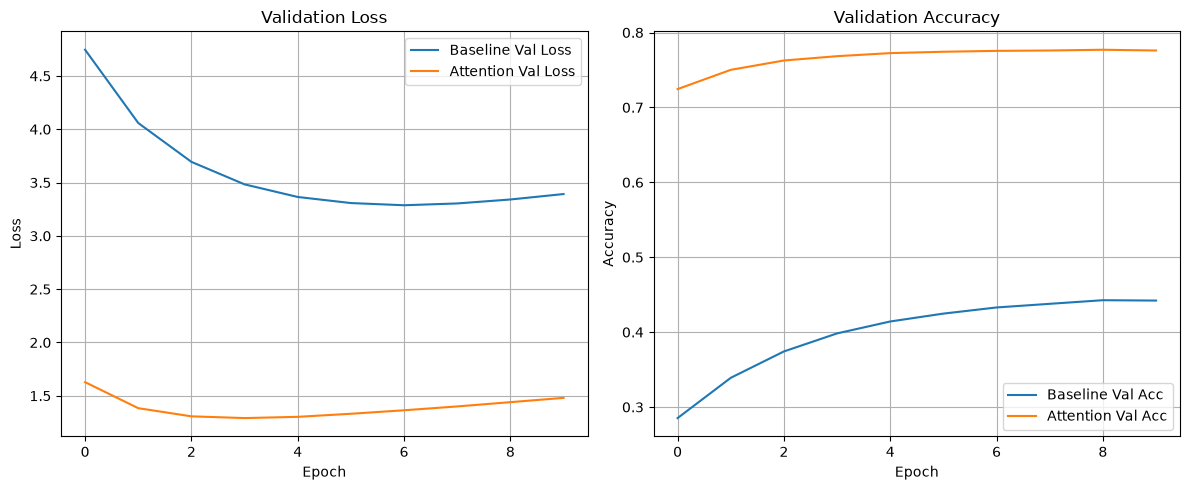

In [27]:
!pip install matplotlib
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['val_loss'], label='Baseline Val Loss')
plt.plot(history_attention.history['val_loss'], label='Attention Val Loss')
plt.title('Validation Loss'); plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['val_accuracy'], label='Baseline Val Acc')
plt.plot(history_attention.history['val_accuracy'], label='Attention Val Acc')
plt.title('Validation Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.legend(); plt.grid(True)

plt.tight_layout()
plt.show()

### 2. Define Inference Models
We'll isolate the encoder and decoder components to generate translations sequentially word-by-word.

In [34]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Concatenate
import numpy as np

# Encoder: returns all outputs + final states
attention_encoder_model = Model(enc_in, [enc_out, enc_h, enc_c])

# Decoder: one step at a time
tok_in    = Input(shape=(1,), name="inf_tok")
h_in      = Input(shape=(LATENT_DIM,), name="inf_h")
c_in      = Input(shape=(LATENT_DIM,), name="inf_c")
encout_in = Input(shape=(32, LATENT_DIM), name="inf_encout")
src_in    = Input(shape=(32,), name="inf_src")

d_out, d_h, d_c = dec_lstm(dec_emb_layer(tok_in), initial_state=[h_in, c_in])
ctx   = attn([d_out, encout_in], mask=[None, src_mask_layer(src_in)])
probs = dense(Concatenate(axis=-1)([d_out, ctx]))

attention_decoder_model = Model([tok_in, h_in, c_in, encout_in, src_in], [probs, d_h, d_c])

### 3. Translation Decoding Function
We'll use greedy decoding to translate input sequences into English.

In [35]:
# Map English index back to text words
reverse_target_word_index = {idx: word for word, idx in decoder_tokenizer.word_index.items()}

def decode_attention_sequence(input_seq):
    enc_outputs, h, c = attention_encoder_model.predict(input_seq, verbose=0)

    target_seq = np.array([[decoder_tokenizer.word_index['<start>']]])
    decoded = []

    for _ in range(MAX_DECODER_LEN):
        probs, h, c = attention_decoder_model.predict(
            [target_seq, h, c, enc_outputs, input_seq], verbose=0)
        idx = int(np.argmax(probs[0, 0, :]))
        word = reverse_target_word_index.get(idx, '<OOV>')
        if word == '<end>':
            break
        if word not in ('<start>', '<pad>'):
            decoded.append(word)
        target_seq = np.array([[idx]])

    return ' '.join(decoded)

### 4. Translation Sample Testing
Let's run our decoder function on a few random samples from the validation dataset to inspect translation quality.

In [39]:
import random

for _ in range(5):
    idx = random.randint(0, len(X_val) - 1)
    input_seq = X_val[idx : idx + 1]

    # Convert Malayalam input token IDs back to words
    malayalam_seq = input_seq[0][input_seq[0] != 0].tolist()
    malayalam_text = ml_tokenizer.sequences_to_texts([malayalam_seq])[0]

    # True target English sentence
    true_english = val_english[idx]

    # Predict with the attention model
    predicted_english = decode_attention_sequence(input_seq)

    print("-" * 70)
    print("Malayalam Source:", malayalam_text)
    print("Ground Truth:", true_english)
    print("Attention Prediction:", predicted_english)
print("-" * 70)

----------------------------------------------------------------------
Malayalam Source: 2021 22ൽ വെർച്വൽ എംപ്ലോയ്മെന്റ് എക്സ്ചേഞ്ച് പ്രോഗ്രാമിന് കീഴിൽ കണ്ണൂർ പത്തനംതിട്ട കൊല്ലം ജില്ലകളിൽ ജോബ് ഫെസ്റ്റ് നടത്തി
Ground Truth: In 2021-22, under virtual employment exchange programme job fest had been conducted at Kannur, Pathanamthitta and Kollam districts.
Attention Prediction: in 2021 22 job opportunities were conducted in various districts of employment exchange of employment exchanges at kannur districts
----------------------------------------------------------------------
Malayalam Source: പ്രാദേശികമായ ജലവിഭവ വിനിയോഗം ജലസംരക്ഷണം പുനഃചംക്രമണം ജലസേചനത്തിന്റെ പരമാവധി പ്രയോജനം വിള പരിപാലനം എന്നിവ ഉള്‍പ്പെടുത്തി സമഗ്രമായ ജലസേചന സംവിധാനം വികസിപ്പിച്ചെടുക്കുക
Ground Truth: Development of irrigation systems incorporating local water resources utilization,water conservation, recycling and optimum methods of irrigation and crop management.
Attention Prediction: watershed management system for w